In [1]:

!pip install -q imdlib xarray netCDF4

import os
import imdlib as imd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:

# ---------------------------------------------------------
# 1. DATA ACQUISITION & SPATIAL AGGREGATION (IMD GRIDDED DATA)
# ---------------------------------------------------------
start_yr = 2010
end_yr = 2020
variable = 'rain'
file_dir = 'imd_data'
os.makedirs(file_dir, exist_ok=True)

print("Downloading real IMD 0.25-deg gridded rainfall data (2010-2020)...")
data = imd.get_data(variable, start_yr, end_yr, fn_format='yearwise', file_dir=file_dir)
ds = data.get_xarray()

lat_bounds = slice(15.50, 16.15)
lon_bounds = slice(74.50, 75.85)
catchment_rain = ds['rain'].sel(lat=lat_bounds, lon=lon_bounds)

catchment_rain = catchment_rain.where(catchment_rain >= 0)
daily_lumped_rain = catchment_rain.mean(dim=['lat', 'lon']).to_dataframe().reset_index()
daily_lumped_rain.rename(columns={'time': 'Date', 'rain': 'Precipitation_mm'}, inplace=True)

daily_lumped_rain['Date'] = pd.to_datetime(daily_lumped_rain['Date'])
df_monthly = daily_lumped_rain.set_index('Date').resample('ME')['Precipitation_mm'].sum().reset_index()



Downloading: rain for year 2010
Downloading: rain for year 2011
Downloading: rain for year 2012
Downloading: rain for year 2013
Downloading: rain for year 2014
Downloading: rain for year 2015
Downloading: rain for year 2016
Downloading: rain for year 2017
Downloading: rain for year 2018
Downloading: rain for year 2019
Downloading: rain for year 2020
Download Successful !!!


In [5]:
# ---------------------------------------------------------
# 2. BASELINE SCS CURVE NUMBER (SCS-CN) MODEL
# ---------------------------------------------------------
CN_baseline = 78.0
S = (25400.0 / CN_baseline) - 254.0
Ia = 0.2 * S

def compute_scs_runoff(P, Ia_val, S_val):
    """Calculates direct surface runoff depth Q (mm) using SCS-CN equation."""
    if P > Ia_val:
        return ((P - Ia_val) ** 2) / (P - Ia_val + S_val)
    return 0.0

daily_lumped_rain['Runoff_mm'] = daily_lumped_rain['Precipitation_mm'].apply(
    lambda p: compute_scs_runoff(p, Ia, S)
)
daily_lumped_rain['Retention_mm'] = daily_lumped_rain['Precipitation_mm'] - daily_lumped_rain['Runoff_mm']

df_monthly = daily_lumped_rain.set_index('Date').resample('ME').sum().reset_index()

df_monthly = df_monthly.round(2)
df_monthly.to_csv('malaprabha_2010_2020_cleaned.csv', index=False)
print("Saved real cleaned data to 'malaprabha_2010_2020_cleaned.csv'")

Saved real cleaned data to 'malaprabha_2010_2020_cleaned.csv'


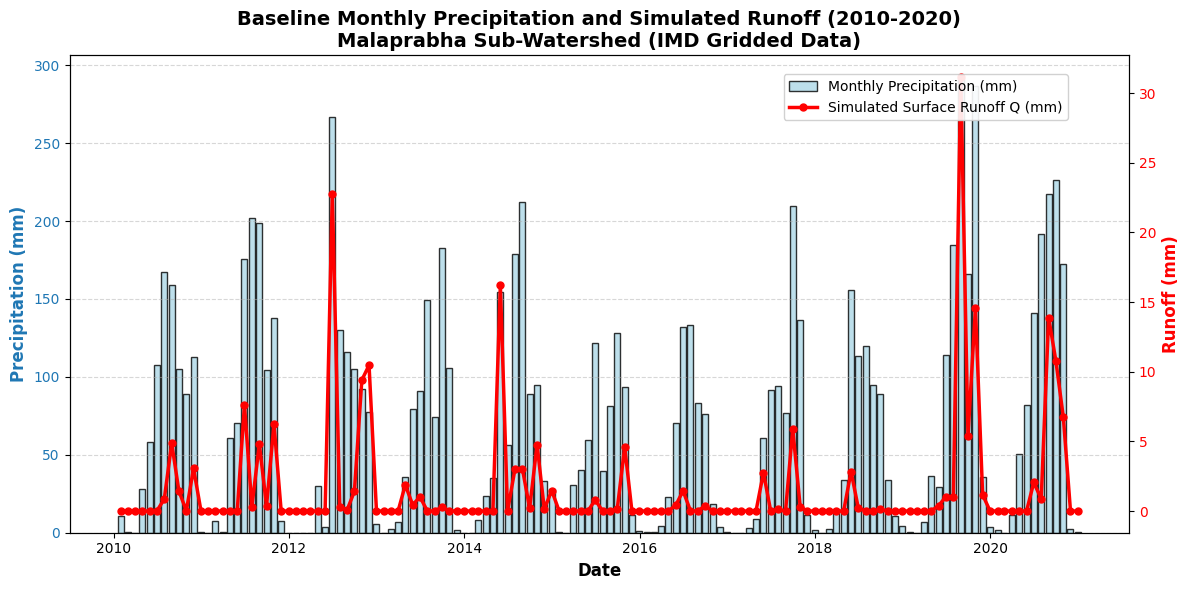

In [7]:
# ---------------------------------------------------------
# 3. VISUALIZATION OF PRELIMINARY BASELINE RESULTS
# ---------------------------------------------------------
df_subset = df_monthly[df_monthly['Date'].dt.year <= 2020]

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    df_subset['Date'], df_subset['Precipitation_mm'],
    width=25, label='Monthly Precipitation (mm)',
    color='lightblue', alpha=0.8, edgecolor='black'
)
ax1.set_xlabel('Date', fontsize=12, fontweight='bold')
ax1.set_ylabel('Precipitation (mm)', fontsize=12, fontweight='bold', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(
    df_subset['Date'], df_subset['Runoff_mm'],
    marker='o', color='red', linewidth=2.5, markersize=5,
    label='Simulated Surface Runoff Q (mm)'
)
ax2.set_ylabel('Runoff (mm)', fontsize=12, fontweight='bold', color='red')
ax2.tick_params(axis='y', labelcolor='red')


plt.title('Baseline Monthly Precipitation and Simulated Runoff (2010-2020)\nMalaprabha Sub-Watershed (IMD Gridded Data)', fontsize=14, fontweight='bold')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88), framealpha=0.9)

plt.tight_layout()
plt.savefig('baseline_runoff_corrected.png', dpi=300)
plt.show()